In [2]:
from pathlib import Path
import requests
import xarray as xr

data_dir = Path("data/soil_moisture")
data_dir.mkdir(parents=True, exist_ok=True)

filename = (
    "ESACCI-SOILMOISTURE-L3S-SSMV-COMBINED-"
    "20100101000000-fv09.2.nc"
)

url = (
    "https://dap.ceda.ac.uk/neodc/esacci/soil_moisture/"
    f"data/daily_files/COMBINED/v09.2/2010/{filename}"
)

file_path = data_dir / filename

if not file_path.exists():
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    file_path.write_bytes(response.content)

print("File:", file_path)
print("Size:", round(file_path.stat().st_size / 1_000_000, 2), "MB")

File: data\soil_moisture\ESACCI-SOILMOISTURE-L3S-SSMV-COMBINED-20100101000000-fv09.2.nc
Size: 1.4 MB


In [3]:
with xr.open_dataset(file_path) as ds:
    print(ds)

    print("\nSoil moisture metadata:")
    print(ds["sm"].attrs)

    print("\nUncertainty metadata:")
    print(ds["sm_uncertainty"].attrs)

<xarray.Dataset> Size: 29MB
Dimensions:         (time: 1, lon: 1440, lat: 720)
Coordinates:
  * time            (time) datetime64[ns] 8B 2010-01-01
  * lon             (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
  * lat             (lat) float32 3kB 89.88 89.62 89.38 ... -89.38 -89.62 -89.88
Data variables:
    sm              (time, lat, lon) float32 4MB ...
    sm_uncertainty  (time, lat, lon) float32 4MB ...
    flag            (time, lat, lon) float32 4MB ...
    freqbandID      (time, lat, lon) int16 2MB ...
    dnflag          (time, lat, lon) int8 1MB ...
    mode            (time, lat, lon) int8 1MB ...
    sensor          (time, lat, lon) int32 4MB ...
    t0              (time, lat, lon) datetime64[ns] 8MB ...
Attributes: (12/44)
    title:                        ESA CCI Surface Soil Moisture COMBINED acti...
    institution:                  TU Wien (AUT); VanderSat B.V. (NL); Planet ...
    contact:                      cci_sm_contact@eodc.eu
    source:   

In [4]:
import pandas as pd
import numpy as np

# Read the locations directly from Jasper's CSV.
original = pd.read_csv("best_cells_8d.csv", parse_dates=["date"])
points = original[["lon", "lat"]].drop_duplicates()

records = []

with xr.open_dataset(file_path) as ds:
    for point in points.itertuples(index=False):
        # Select the nearest satellite grid-cell centre.
        cell = ds.sel(lon=point.lon, lat=point.lat, method="nearest")

        selected_lon = float(cell["lon"].item())
        selected_lat = float(cell["lat"].item())

        # Verify that the selected coordinates match our requested cell.
        assert np.isclose(selected_lon, point.lon)
        assert np.isclose(selected_lat, point.lat)

        records.append({
            "date": pd.Timestamp(cell["time"].values[0]),
            "lon": selected_lon,
            "lat": selected_lat,
            "sm": float(cell["sm"].isel(time=0).item()),
            "sm_uncertainty": float(
                cell["sm_uncertainty"].isel(time=0).item()
            ),
        })

test_points = pd.DataFrame(records)

# Keep only observations with valid SM and acceptable uncertainty.
test_points["passes_filter"] = (
    test_points["sm"].between(0, 1)
    & test_points["sm_uncertainty"].between(0, 0.025)
)

test_points["sm_filtered"] = test_points["sm"].where(
    test_points["passes_filter"]
)

display(test_points)

,date,lon,lat,sm,sm_uncertainty,passes_filter,sm_filtered
0,2010-01-01,-4.125,41.375,0.164472,0.012373,True,0.164472
1,2010-01-01,2.125,45.875,NaN,NaN,False,NaN
2,2010-01-01,-9.125,52.125,NaN,NaN,False,NaN


In [5]:
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

dates = pd.date_range("2010-01-01", "2011-12-31", freq="D")

# Retry temporary connection/server failures.
session = requests.Session()
retry = Retry(
    total=3,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
)
session.mount("https://", HTTPAdapter(max_retries=retry))

failed = []

for i, date in enumerate(dates, start=1):
    filename = (
        "ESACCI-SOILMOISTURE-L3S-SSMV-COMBINED-"
        f"{date:%Y%m%d}000000-fv09.2.nc"
    )

    destination = data_dir / filename

    if destination.exists() and destination.stat().st_size > 0:
        continue

    url = (
        "https://dap.ceda.ac.uk/neodc/esacci/soil_moisture/"
        f"data/daily_files/COMBINED/v09.2/{date.year}/{filename}"
    )

    # Write to a temporary file so interrupted downloads aren't
    # mistaken for completed files.
    temporary = destination.with_suffix(".nc.part")

    try:
        with session.get(url, stream=True, timeout=(30, 120)) as response:
            response.raise_for_status()

            with temporary.open("wb") as output:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        output.write(chunk)

        # Check that the downloaded file opens and contains our variables.
        with xr.open_dataset(temporary) as check:
            assert {"sm", "sm_uncertainty"}.issubset(check.data_vars)
            assert pd.Timestamp(check.time.values[0]).normalize() == date

        temporary.replace(destination)

    except Exception as error:
        temporary.unlink(missing_ok=True)
        failed.append({
            "date": date,
            "error": str(error),
        })
        print(f"Failed: {date:%Y-%m-%d}: {error}")

    if i % 50 == 0 or i == len(dates):
        print(f"Checked {i}/{len(dates)} dates")

session.close()

failed_downloads = pd.DataFrame(failed, columns=["date", "error"])

print("\nDownload pass finished.")
print("Failed downloads:", len(failed_downloads))
display(failed_downloads)

Checked 50/730 dates
Checked 100/730 dates
Checked 150/730 dates
Checked 200/730 dates
Checked 250/730 dates
Checked 300/730 dates
Checked 350/730 dates
Checked 400/730 dates
Checked 450/730 dates
Checked 500/730 dates
Checked 550/730 dates
Checked 600/730 dates
Checked 650/730 dates
Checked 700/730 dates
Checked 730/730 dates

Download pass finished.
Failed downloads: 0


,date,error


In [6]:
daily_records = []

for i, date in enumerate(dates, start=1):
    filename = (
        "ESACCI-SOILMOISTURE-L3S-SSMV-COMBINED-"
        f"{date:%Y%m%d}000000-fv09.2.nc"
    )

    with xr.open_dataset(data_dir / filename) as ds:
        file_date = pd.Timestamp(ds["time"].values[0]).normalize()
        assert file_date == date

        for point in points.itertuples(index=False):
            cell = ds.sel(
                lon=point.lon,
                lat=point.lat,
                method="nearest",
            )

            assert np.isclose(float(cell.lon.item()), point.lon)
            assert np.isclose(float(cell.lat.item()), point.lat)

            daily_records.append({
                "date": file_date,
                "lon": point.lon,
                "lat": point.lat,
                "sm": float(cell["sm"].isel(time=0).item()),
                "sm_uncertainty": float(
                    cell["sm_uncertainty"].isel(time=0).item()
                ),
            })

    if i % 100 == 0 or i == len(dates):
        print(f"Extracted {i}/{len(dates)} days")

daily_sm = (
    pd.DataFrame(daily_records)
    .sort_values(["lon", "lat", "date"])
    .reset_index(drop=True)
)

# Apply the uncertainty threshold and valid-range checks.
daily_sm["passes_filter"] = (
    daily_sm["sm"].between(0, 1)
    & daily_sm["sm_uncertainty"].between(0, 0.025)
)

daily_sm["sm_filtered"] = daily_sm["sm"].where(
    daily_sm["passes_filter"]
)

# Verify one record per location per day.
assert len(daily_sm) == 730 * len(points)
assert not daily_sm.duplicated(["lon", "lat", "date"]).any()

# Save the extracted data separately from Jasper's original CSV.
daily_sm.to_csv("soil_moisture_daily_extracted.csv", index=False)

summary = (
    daily_sm.groupby(["lon", "lat"])
    .agg(
        total_days=("date", "size"),
        available_sm=("sm", "count"),
        valid_after_filter=("sm_filtered", "count"),
    )
    .reset_index()
)

display(summary)
display(daily_sm.head())

Extracted 100/730 days
Extracted 200/730 days
Extracted 300/730 days
Extracted 400/730 days
Extracted 500/730 days
Extracted 600/730 days
Extracted 700/730 days
Extracted 730/730 days


,lon,lat,total_days,available_sm,valid_after_filter
0,-9.125,52.125,730,623,599
1,-4.125,41.375,730,669,655
2,2.125,45.875,730,563,538


,date,lon,lat,sm,sm_uncertainty,passes_filter,sm_filtered
0,2010-01-01,-9.125,52.125,NaN,NaN,False,NaN
1,2010-01-02,-9.125,52.125,NaN,NaN,False,NaN
2,2010-01-03,-9.125,52.125,0.37574,0.006278,True,0.37574
3,2010-01-04,-9.125,52.125,NaN,NaN,False,NaN
4,2010-01-05,-9.125,52.125,NaN,NaN,False,NaN


In [7]:
window_records = []

for row in original[["lon", "lat", "date"]].itertuples(index=False):
    start = row.date
    end = start + pd.Timedelta(days=8)

    # Include the start date; exclude the next window's start.
    window = daily_sm.loc[
        (daily_sm["lon"] == row.lon)
        & (daily_sm["lat"] == row.lat)
        & (daily_sm["date"] >= start)
        & (daily_sm["date"] < end)
    ]

    valid_days = window["sm_filtered"].count()

    window_records.append({
        "lon": row.lon,
        "lat": row.lat,
        "date": start,
        "sm_days_in_record": len(window),
        "sm_valid_days": valid_days,
        "sm": (
            window["sm_filtered"].mean()
            if valid_days >= 5
            else np.nan
        ),
    })

sm_8d = pd.DataFrame(window_records)

# Preserve Jasper's supplied SM for comparison.
prepared = original.rename(columns={"sm": "sm_supplied"}).merge(
    sm_8d,
    on=["lon", "lat", "date"],
    how="left",
    validate="one_to_one",
)

prepared["dTa"] = prepared["tx"] - prepared["tn"]

assert len(prepared) == len(original)

display(
    prepared.groupby(["lon", "lat"]).agg(
        total_windows=("date", "size"),
        supplied_sm_windows=("sm_supplied", "count"),
        calculated_sm_windows=("sm", "count"),
    )
)

# Compare only windows where both versions have values.
comparison = prepared.dropna(subset=["sm", "sm_supplied"]).copy()
comparison["absolute_difference"] = (
    comparison["sm"] - comparison["sm_supplied"]
).abs()

display(
    comparison.groupby(["lon", "lat"]).agg(
        compared_windows=("sm", "size"),
        mean_absolute_difference=("absolute_difference", "mean"),
        maximum_absolute_difference=("absolute_difference", "max"),
    )
)

# Inspect windows with fewer than eight days in our downloaded record.
display(
    prepared.loc[
        prepared["sm_days_in_record"] < 8,
        ["lon", "lat", "date", "sm_days_in_record", "sm_valid_days", "sm"]
    ]
)

prepared.to_csv("best_cells_8d_prepared.csv", index=False)

,,total_windows,supplied_sm_windows,calculated_sm_windows
lon,lat,,,
-9.125,52.125,92,81,79
-4.125,41.375,92,87,86
2.125,45.875,92,70,69


,,compared_windows,mean_absolute_difference,maximum_absolute_difference
lon,lat,,,
-9.125,52.125,78,0.002090,0.015297
-4.125,41.375,85,0.004015,0.025640
2.125,45.875,68,0.003850,0.026722


,lon,lat,date,sm_days_in_record,sm_valid_days,sm
91,-4.125,41.375,2011-12-30,2,0,NaN
183,2.125,45.875,2011-12-30,2,0,NaN
275,-9.125,52.125,2011-12-30,2,2,NaN


In [8]:
alignment_results = []

# Offsets relative to each CSV date.
# Each interval includes its start and excludes its end.
alignments = {
    "start-labelled": (0, 8),
    "centre-labelled": (-4, 4),
    "end-labelled": (-7, 1),
}

for label, (start_offset, end_offset) in alignments.items():
    records = []

    for row in original.itertuples(index=False):
        start = row.date + pd.Timedelta(days=start_offset)
        end = row.date + pd.Timedelta(days=end_offset)

        window = daily_sm.loc[
            (daily_sm["lon"] == row.lon)
            & (daily_sm["lat"] == row.lat)
            & (daily_sm["date"] >= start)
            & (daily_sm["date"] < end)
        ]

        # Use full windows for this alignment comparison.
        if len(window) != 8:
            continue

        values = window["sm_filtered"]
        calculated = values.mean() if values.count() >= 5 else np.nan

        records.append({
            "lon": row.lon,
            "lat": row.lat,
            "date": row.date,
            "calculated": calculated,
            "supplied": row.sm,
        })

    result = pd.DataFrame(records).dropna(
        subset=["calculated", "supplied"]
    )
    result["absolute_difference"] = (
        result["calculated"] - result["supplied"]
    ).abs()

    summary_alignment = (
        result.groupby(["lon", "lat"])
        .agg(
            compared_windows=("calculated", "size"),
            mean_absolute_difference=("absolute_difference", "mean"),
        )
        .reset_index()
    )

    summary_alignment["alignment"] = label
    alignment_results.append(summary_alignment)

alignment_check = pd.concat(alignment_results, ignore_index=True)

display(
    alignment_check.pivot(
        index=["lon", "lat"],
        columns="alignment",
        values="mean_absolute_difference",
    ).round(6)
)

,alignment,centre-labelled,end-labelled,start-labelled
lon,lat,,,
-9.125,52.125,0.004681,0.006662,0.002090
-4.125,41.375,0.007371,0.013105,0.004015
2.125,45.875,0.006579,0.012550,0.003850


In [9]:
predictors = ["lai", "sm", "hu", "tg"]

prepared["year"] = prepared["date"].dt.year

# Same complete observations for every candidate model.
prepared["complete_case"] = prepared[
    ["dTa"] + predictors
].notna().all(axis=1)

sample_counts = (
    prepared.groupby(["lon", "lat", "year"])
    .agg(
        total_windows=("date", "size"),
        complete_windows=("complete_case", "sum"),
    )
    .reset_index()
)

display(sample_counts)

prepared.to_csv("best_cells_8d_prepared.csv", index=False)

,lon,lat,year,total_windows,complete_windows
0,-9.125,52.125,2010,46,38
1,-9.125,52.125,2011,46,41
2,-4.125,41.375,2010,46,43
3,-4.125,41.375,2011,46,43
4,2.125,45.875,2010,46,34
5,2.125,45.875,2011,46,35


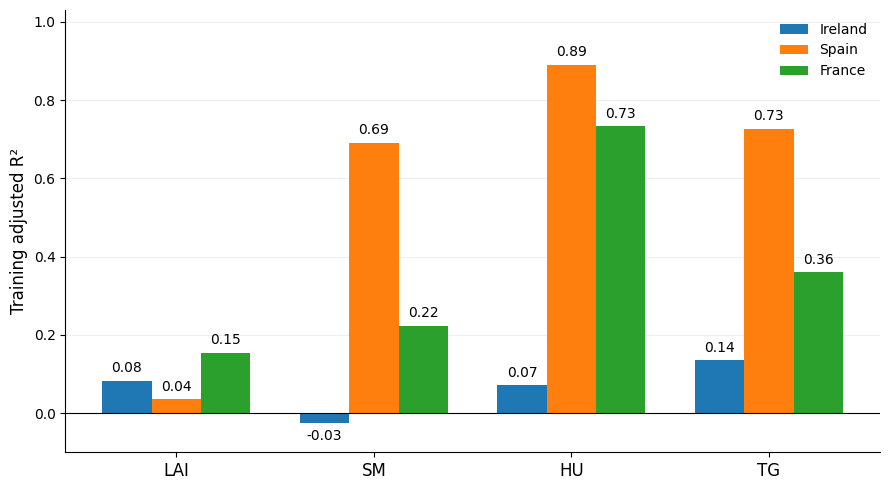

In [1]:
import numpy as np
import matplotlib.pyplot as plt

predictor_labels = ["LAI", "SM", "HU", "TG"]

scores = {
    "Ireland": [0.0830, -0.0261, 0.0710, 0.1356],
    "Spain":   [0.0352, 0.6902, 0.8903, 0.7272],
    "France":  [0.1546, 0.2235, 0.7333, 0.3603],
}

colors = {
    "Ireland": "tab:blue",
    "Spain": "tab:orange",
    "France": "tab:green",
}

x = np.arange(len(predictor_labels))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))

for i, (location, values) in enumerate(scores.items()):
    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=location,
        color=colors[location],
    )
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=10)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(predictor_labels, fontsize=12)
ax.set_ylabel("Training adjusted R²", fontsize=12)
ax.set_ylim(-0.10, 1.03)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(
    "single_predictor_grouped_bars.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

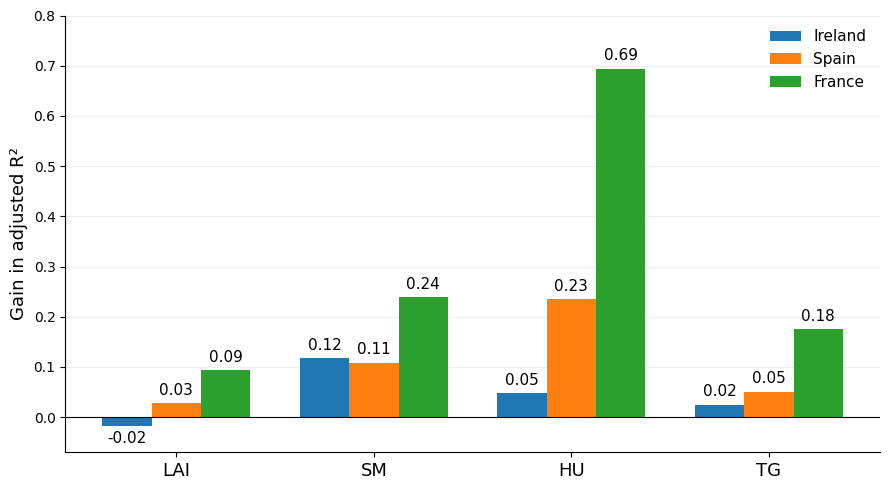

In [2]:
import numpy as np
import matplotlib.pyplot as plt

labels = ["LAI", "SM", "HU", "TG"]

gains = {
    "Ireland": [-0.0172, 0.1171, 0.0471, 0.0245],
    "Spain":   [0.0273, 0.1088, 0.2348, 0.0506],
    "France":  [0.0930, 0.2384, 0.6943, 0.1752],
}

colors = ["tab:blue", "tab:orange", "tab:green"]
x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))

for i, ((country, values), color) in enumerate(
    zip(gains.items(), colors)
):
    bars = ax.bar(
        x + (i - 1) * width, values, width,
        label=country, color=color,
    )
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=11)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=13)
ax.set_ylabel("Gain in adjusted R²", fontsize=13)
ax.set_ylim(-0.07, 0.80)
ax.legend(frameon=False, fontsize=11)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(
    "gain_beyond_seasonality.png",
    dpi=300, bbox_inches="tight", facecolor="white",
)
plt.show()

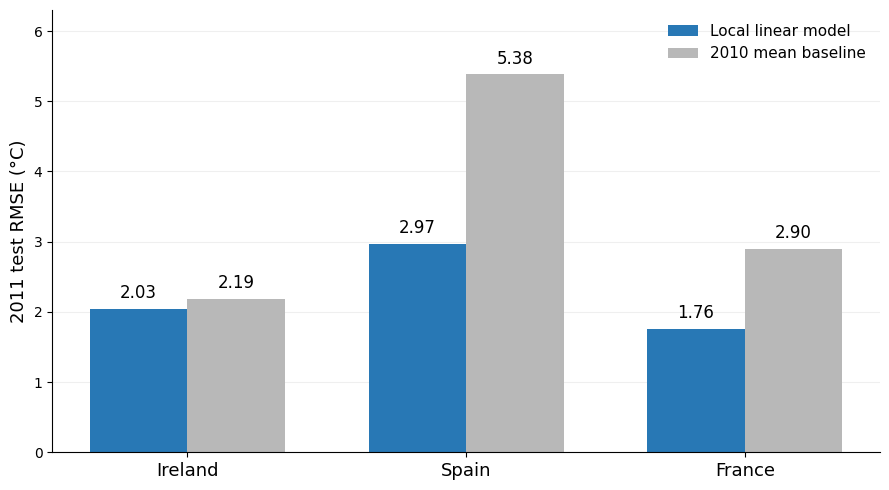

In [3]:
import numpy as np
import matplotlib.pyplot as plt

locations = ["Ireland", "Spain", "France"]
local_rmse = [2.0347, 2.9706, 1.7630]
baseline_rmse = [2.1889, 5.3818, 2.8986]

x = np.arange(len(locations))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_local = ax.bar(
    x - width / 2, local_rmse, width,
    label="Local linear model", color="#2878B5",
)
bars_baseline = ax.bar(
    x + width / 2, baseline_rmse, width,
    label="2010 mean baseline", color="#B8B8B8",
)

for bars in [bars_local, bars_baseline]:
    ax.bar_label(bars, fmt="%.2f", padding=5, fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(locations, fontsize=13)
ax.set_ylabel("2011 test RMSE (°C)", fontsize=13)
ax.set_ylim(0, 6.3)
ax.legend(frameon=False, fontsize=11)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(
    "local_models_vs_baseline.png",
    dpi=300, bbox_inches="tight", facecolor="white",
)
plt.show()

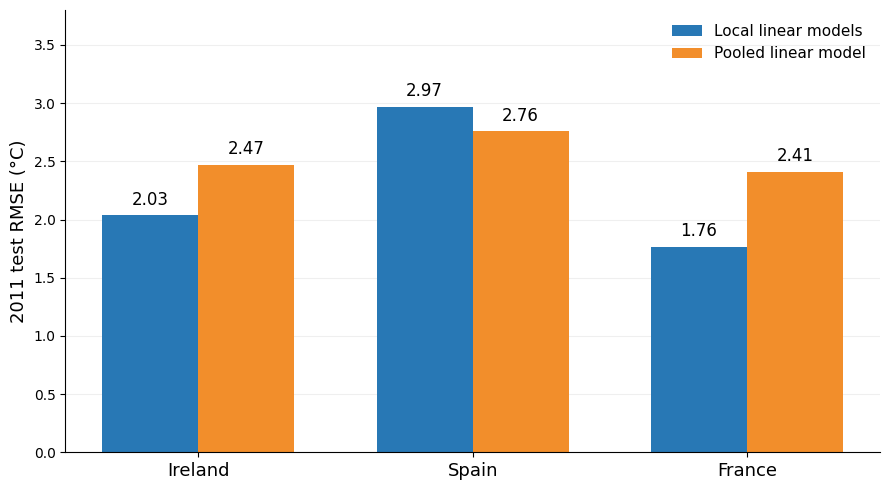

In [4]:
import numpy as np
import matplotlib.pyplot as plt

locations = ["Ireland", "Spain", "France"]
local_rmse = [2.0347, 2.9706, 1.7630]
pooled_rmse = [2.4710, 2.7564, 2.4072]

x = np.arange(len(locations))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

local_bars = ax.bar(
    x - width / 2, local_rmse, width,
    label="Local linear models", color="#2878B5",
)
pooled_bars = ax.bar(
    x + width / 2, pooled_rmse, width,
    label="Pooled linear model", color="#F28E2B",
)

for bars in [local_bars, pooled_bars]:
    ax.bar_label(bars, fmt="%.2f", padding=5, fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(locations, fontsize=13)
ax.set_ylabel("2011 test RMSE (°C)", fontsize=13)
ax.set_ylim(0, 3.8)
ax.legend(frameon=False, fontsize=11)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(
    "local_vs_pooled_rmse.png",
    dpi=300, bbox_inches="tight", facecolor="white",
)
plt.show()

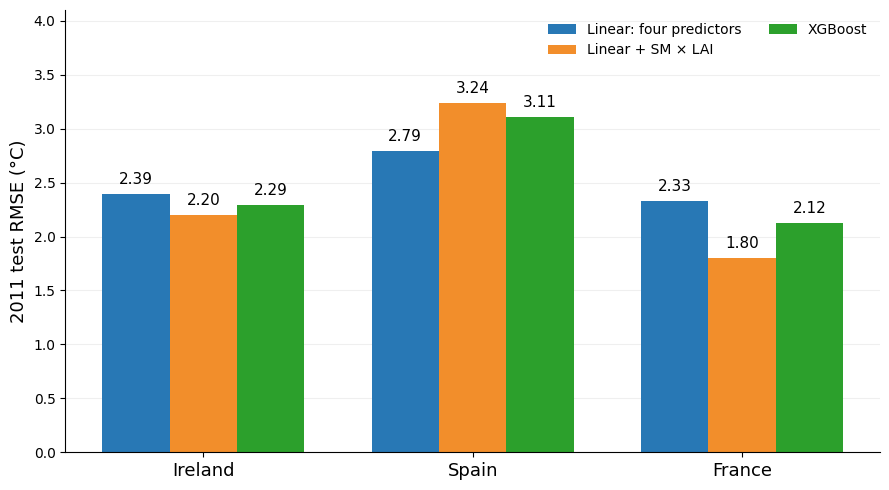

In [5]:
import numpy as np
import matplotlib.pyplot as plt

locations = ["Ireland", "Spain", "France"]

scores = {
    "Linear: four predictors": [2.392, 2.792, 2.329],
    "Linear + SM × LAI": [2.200, 3.242, 1.800],
    "XGBoost": [2.293, 3.112, 2.124],
}

colors = ["#2878B5", "#F28E2B", "#2CA02C"]
x = np.arange(len(locations))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))

for i, ((name, values), color) in enumerate(
    zip(scores.items(), colors)
):
    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=name,
        color=color,
    )
    ax.bar_label(bars, fmt="%.2f", padding=5, fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(locations, fontsize=13)
ax.set_ylabel("2011 test RMSE (°C)", fontsize=13)
ax.set_ylim(0, 4.1)
ax.legend(frameon=False, fontsize=10, ncol=2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(
    "optional_models_rmse.png",
    dpi=300, bbox_inches="tight", facecolor="white",
)
plt.show()

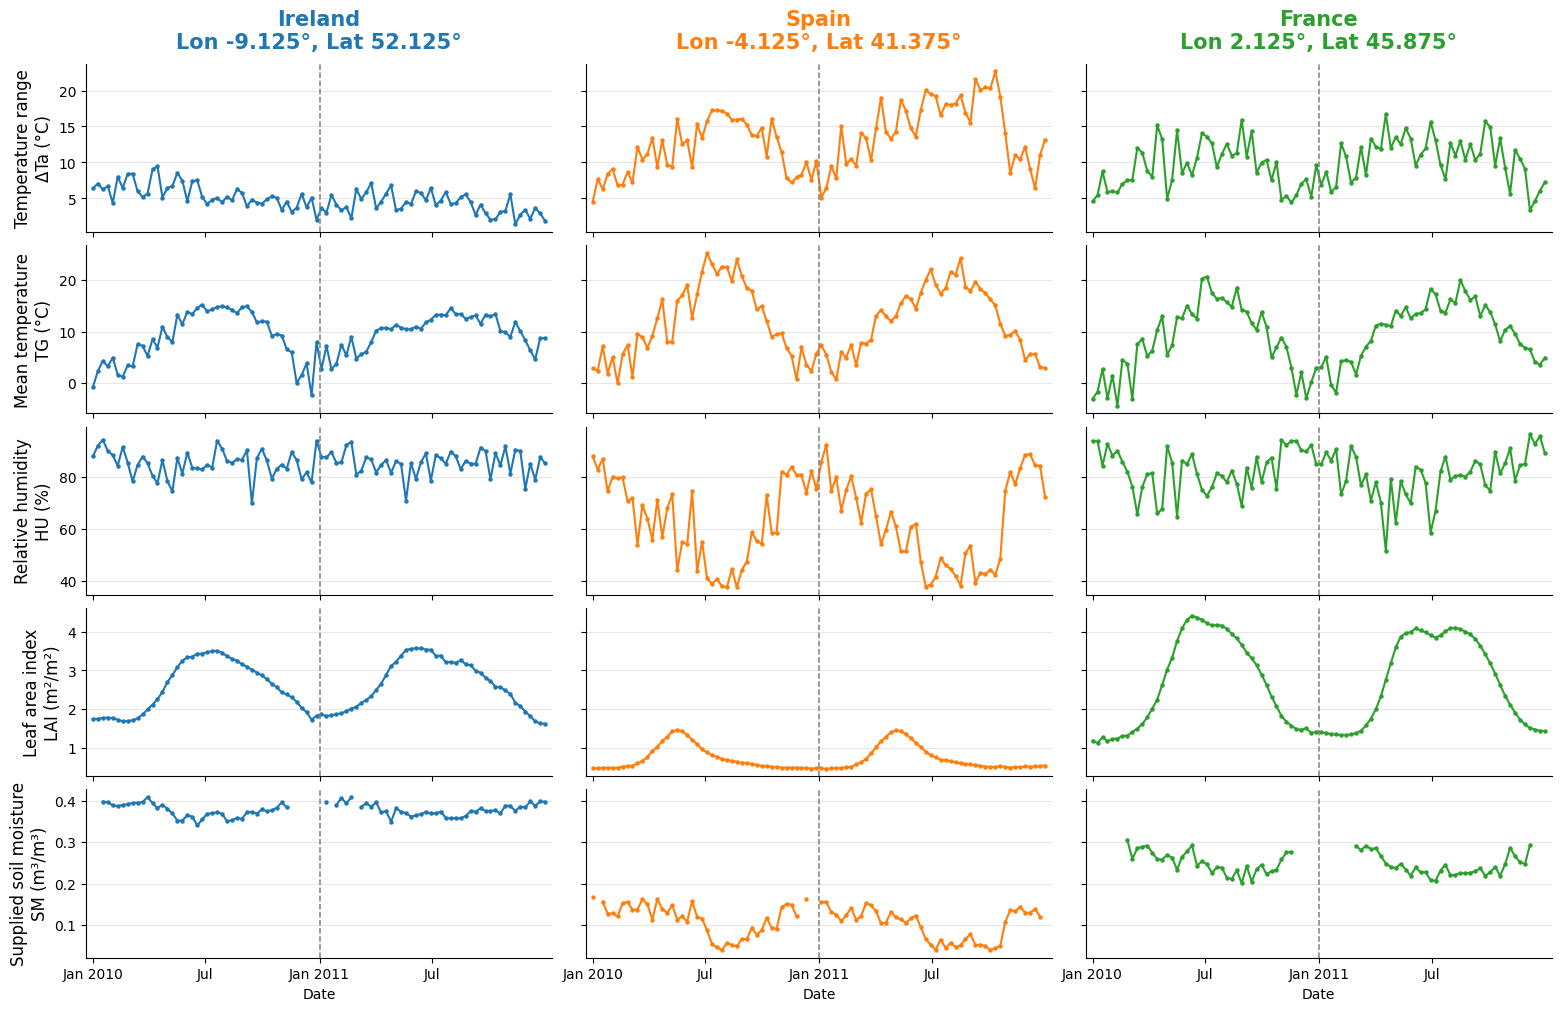

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load and prepare data.
df = pd.read_csv("best_cells_8d.csv", parse_dates=["date"])
df["dTa"] = df["tx"] - df["tn"]

locations = [
    (-9.125, 52.125, "Ireland", "tab:blue"),
    (-4.125, 41.375, "Spain", "tab:orange"),
    (2.125, 45.875, "France", "tab:green"),
]

variables = [
    ("dTa", "Temperature range\nΔTa (°C)"),
    ("tg", "Mean temperature\nTG (°C)"),
    ("hu", "Relative humidity\nHU (%)"),
    ("lai", "Leaf area index\nLAI (m²/m²)"),
    ("sm", "Supplied soil moisture\nSM (m³/m³)"),
]

fig, axes = plt.subplots(
    5, 3,
    figsize=(15.5, 10),
    sharex=True,
    sharey="row",
    constrained_layout=True,
)

for column, (lon, lat, country, colour) in enumerate(locations):
    cell = df.loc[
        (df["lon"] == lon) & (df["lat"] == lat)
    ].sort_values("date")

    for row, (variable, ylabel) in enumerate(variables):
        ax = axes[row, column]

        ax.plot(
            cell["date"],
            cell[variable],
            color=colour,
            linewidth=1.5,
            marker="o",
            markersize=2.2,
        )

        # Separate the training and testing years.
        ax.axvline(
            pd.Timestamp("2011-01-01"),
            color="grey",
            linestyle="--",
            linewidth=1.1,
        )

        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.margins(x=0.015)

        if column == 0:
            ax.set_ylabel(ylabel, fontsize=12)

        if row == 0:
            ax.set_title(
                f"{country}\nLon {lon}°, Lat {lat}°",
                color=colour,
                fontsize=15,
                fontweight="bold",
                pad=11,
            )

        if row == 4:
            ax.set_xticks(pd.to_datetime([
                "2010-01-01",
                "2010-07-01",
                "2011-01-01",
                "2011-07-01",
            ]))
            ax.set_xticklabels([
                "Jan 2010", "Jul", "Jan 2011", "Jul"
            ])
            ax.set_xlabel("Date")

fig.savefig(
    "Environmental_Conditions_Five_Rows_Labelled.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()